# Case Study: Monthly Passenger Counts

Explore trend and seasonality in a small subset of the public flights dataset.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Case study questions
- How do monthly passenger counts change over time?
- Are some months consistently busier within this preview?
- How can year-over-year comparisons be summarized?

**Dataset note:** `flights_sample.csv` contains the first four years of the public seaborn-data flights dataset (1949–1952), with monthly totals. Set `USE_FULL_DATASET = True` to load the full public CSV when internet is available.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR_CANDIDATES = [Path.cwd()/"datasets", Path.cwd().parent/"datasets", Path.cwd().parent.parent/"datasets"]
DATA_DIR = next((p for p in DATA_DIR_CANDIDATES if (p/"flights_sample.csv").exists()), DATA_DIR_CANDIDATES[0])
FLIGHTS_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/flights.csv"
USE_FULL_DATASET = False
flights = pd.read_csv(FLIGHTS_URL) if USE_FULL_DATASET else pd.read_csv(DATA_DIR/"flights_sample.csv")
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
flights["month"] = pd.Categorical(flights["month"], categories=month_order, ordered=True)
flights["date"] = pd.to_datetime(flights["year"].astype(str) + "-" + flights["month"].astype(str), format="%Y-%b")
print("Rows:", len(flights))
display(flights.head())

Rows: 48


,year,month,passengers,date
0,1949,Jan,112,1949-01-01
1,1949,Feb,118,1949-02-01
2,1949,Mar,132,1949-03-01
3,1949,Apr,129,1949-04-01
4,1949,May,121,1949-05-01


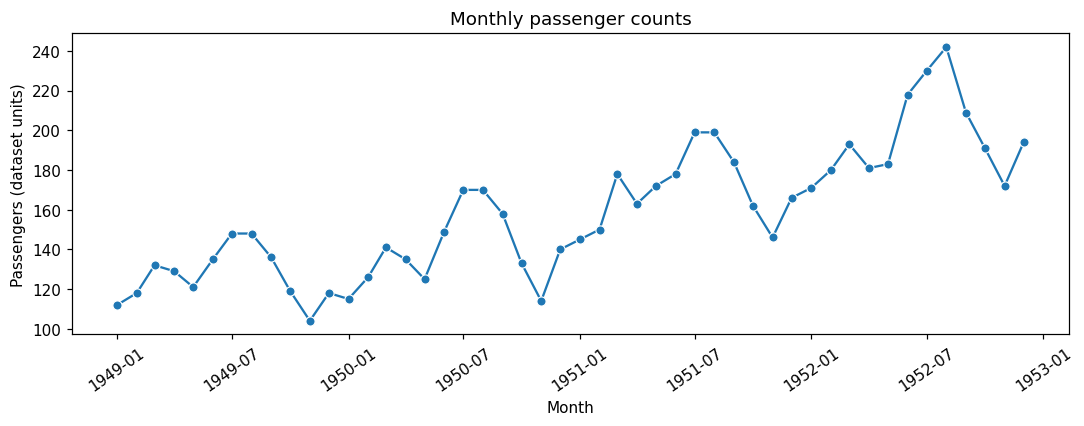

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=flights, x="date", y="passengers", marker="o", ax=ax)
ax.set_title("Monthly passenger counts")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (dataset units)")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

,month,passengers
0,Jan,135.8
1,Feb,143.5
2,Mar,161.0
3,Apr,152.0
4,May,150.2
5,Jun,170.0
6,Jul,186.8
7,Aug,189.8
8,Sep,171.8
9,Oct,151.2


year,1949,1950,1951,1952
month,,,,
Jan,112,115,145,171
Feb,118,126,150,180
Mar,132,141,178,193
Apr,129,135,163,181
May,121,125,172,183
Jun,135,149,178,218
Jul,148,170,199,230
Aug,148,170,199,242
Sep,136,158,184,209


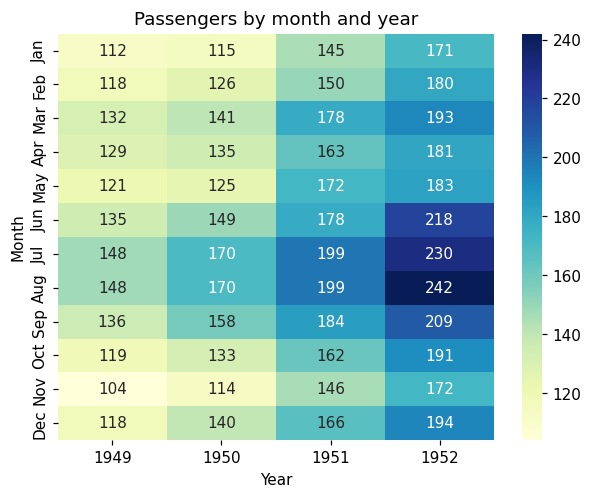

In [3]:
monthly_pattern = flights.groupby("month", observed=False, as_index=False)["passengers"].mean()
yearly = flights.pivot(index="month", columns="year", values="passengers")
display(monthly_pattern.round(1))
display(yearly)

sns.heatmap(yearly, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Passengers by month and year")
plt.xlabel("Year")
plt.ylabel("Month")
plt.show()

## Interpretation checklist
This is a descriptive exercise, not a forecasting task. With only four years, be cautious about claims of long-term trends. Counts may be affected by many factors not represented in the data, and any comparison should use consistent units and time coverage.

In [4]:
flights = flights.sort_values("date")
flights["previous_year"] = flights["passengers"].shift(12)
flights["year_over_year_change"] = flights["passengers"] - flights["previous_year"]
flights["year_over_year_pct"] = 100 * flights["year_over_year_change"] / flights["previous_year"]
display(flights[["date", "passengers", "previous_year", "year_over_year_pct"]].tail(18).round(1))

,date,passengers,previous_year,year_over_year_pct
30,1951-07-01,199,170.0,17.1
31,1951-08-01,199,170.0,17.1
32,1951-09-01,184,158.0,16.5
33,1951-10-01,162,133.0,21.8
34,1951-11-01,146,114.0,28.1
35,1951-12-01,166,140.0,18.6
36,1952-01-01,171,145.0,17.9
37,1952-02-01,180,150.0,20.0
38,1952-03-01,193,178.0,8.4
39,1952-04-01,181,163.0,11.0


## Practice
Calculate mean passengers by month, identify the highest month in the loaded sample, and state whether the sample period is enough to establish a stable seasonal pattern.

In [5]:
mean_by_month = flights.groupby("month", observed=False)["passengers"].mean().sort_values(ascending=False)
display(mean_by_month.to_frame("mean_passengers").round(1))
print("Highest mean month in this sample:", mean_by_month.index[0])

Highest mean month in this sample: Aug


,mean_passengers
month,
Aug,189.8
Jul,186.8
Sep,171.8
Jun,170.0
Mar,161.0
Dec,154.5
Apr,152.0
Oct,151.2
May,150.2
